In [33]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
rows, cols = img.shape
cy, cx = rows // 2, cols // 2

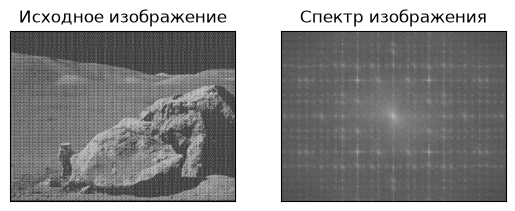

In [34]:
dft = cv.dft(np.float32(img), flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]) + 1)

plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Спектр изображения'), plt.xticks([]), plt.yticks([])
plt.show()

# 1. Реализация высокочастотной фильтрации на основе ядра Гаусса

In [35]:
sigma = 40
u, v = np.meshgrid(np.arange(cols), np.arange(rows))
D2 = (u - cx)**2 + (v - cy)**2

low_pass = np.exp(-D2 / (2*sigma**2))
high_pass = 1 - low_pass

mask_hp = np.zeros((rows, cols, 2), np.float32)
mask_hp[:,:,0] = high_pass
mask_hp[:,:,1] = high_pass

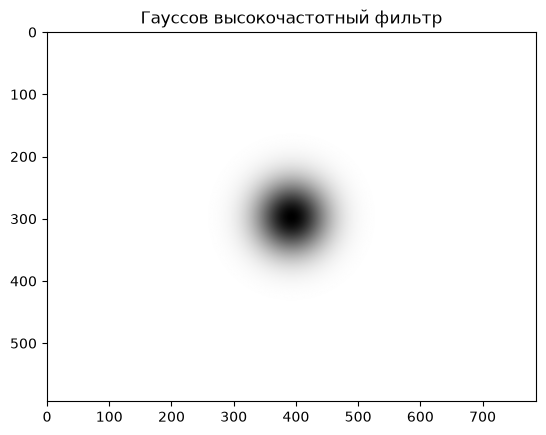

In [36]:
plt.imshow(high_pass, cmap = 'gray')
plt.title('Гауссов высокочастотный фильтр')
plt.show()

In [37]:
dft_hp = dft_shift*mask_hp

hp_magn_res = 20*np.log(cv.magnitude(dft_hp[:,:,0], dft_hp[:,:,1]) + 1)

f_ishift = np.fft.ifftshift(dft_hp)
hp_back = cv.idft(f_ishift, flags = cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)
hp_result = cv.normalize(hp_back, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

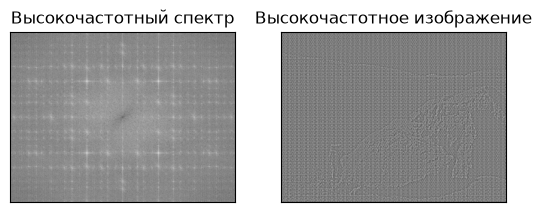

In [38]:
plt.subplot(121),plt.imshow(hp_magn_res, cmap = 'gray')
plt.title('Высокочастотный спектр'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(hp_result, cmap = 'gray')
plt.title('Высокочастотное изображение'), plt.xticks([]), plt.yticks([])
plt.show()

# 2. Реализация свертки через преобразование Фурье

In [39]:
def fft_convolution(image, kernel):
    A = np.float32(image)
    K = np.float32(kernel)
    kh, kw = K.shape

    K_big = np.zeros_like(A)
    K_big[:kh, :kw] = K
    K_big = np.roll(K_big, (-(kh // 2), -(kw // 2)), axis = (0, 1))

    A_dft = cv.dft(A, flags = cv.DFT_COMPLEX_OUTPUT)
    K_dft = cv.dft(K_big, flags = cv.DFT_COMPLEX_OUTPUT)

    prod = cv.mulSpectrums(A_dft, K_dft, 0)

    return cv.idft(prod, flags = cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)

0.00012207031


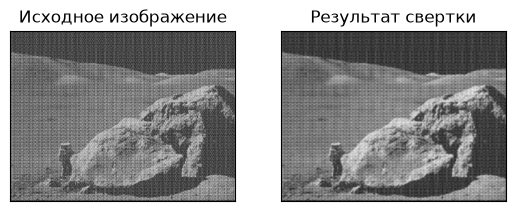

In [40]:
kernel = np.ones((5, 5), np.float32) / 25

conv_fft = fft_convolution(img, kernel)
conv_cv = cv.filter2D(np.float32(img), -1, kernel)

print(np.abs(conv_fft - conv_cv)[5:-5, 5:-5].max())

plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(conv_fft, cmap = 'gray')
plt.title('Результат свертки'), plt.xticks([]), plt.yticks([])
plt.show()

# 3. Реализация удаления периодического шума с помощью преобразования Фурье

In [41]:
local_max = cv.dilate(magnitude_spectrum, np.ones((31, 31), np.uint8))
peaks = np.argwhere((magnitude_spectrum == local_max) & (magnitude_spectrum > 232))

mask = np.ones((rows, cols, 2), np.uint8)
for py, px in peaks:
    if np.hypot(py - cy, px - cx) > 40:
        cv.circle(mask, (int(px), int(py)), 10, (0, 0), -1)

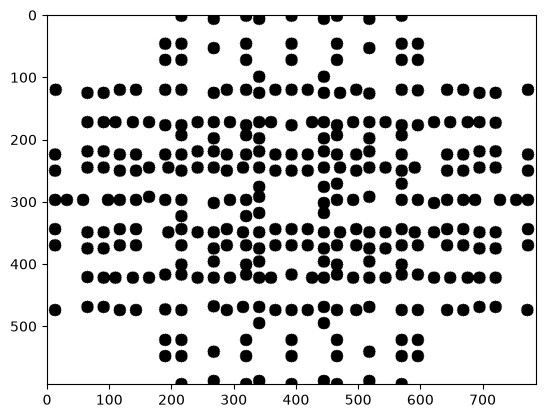

In [42]:
plt.imshow(mask[:,:,0], cmap = 'gray')
plt.show()

In [43]:
dft_clean = dft_shift*mask

clean_magn_res = 20*np.log(cv.magnitude(dft_clean[:,:,0], dft_clean[:,:,1]) + 1)

f_ishift = np.fft.ifftshift(dft_clean)
img_clean = cv.idft(f_ishift, flags = cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)

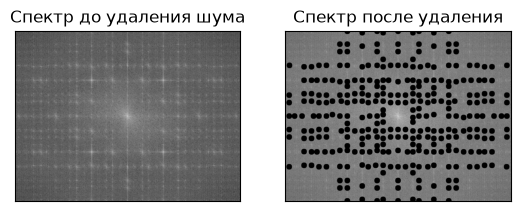

In [44]:
plt.subplot(121),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Спектр до удаления шума'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(clean_magn_res, cmap = 'gray')
plt.title('Спектр после удаления'), plt.xticks([]), plt.yticks([])
plt.show()

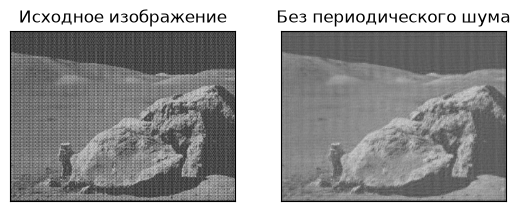

In [45]:
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(img_clean, cmap = 'gray')
plt.title('Без периодического шума'), plt.xticks([]), plt.yticks([])
plt.show()